# GEOG 202 - Wx Balloon Launch 
```
Balloon launch on Wednesday, 23 September 2026.

Station Name             : Bull Street Garage 23 September 2026
.       Latitude         : 33�59'43.0"N
.       Longitude        : 081�01'33.0"W
.       Altitude (MSL)   : 96m

Sonde   Type             : iMet-4-AB
.       Serial Number    : 71841

Surface Pressure         : 1011.75hPa
.       Temperature      : +22.2�C
.       Humidity         : 69%
.       Wind Speed       : 8.0kts
.       Wind Direction   : 20.0�
.       Cloud Code       : /////

Flight

.         Launched (UTC) : 23/09/2026 4:10:31 PM
.      Termination (UTC) : 3/17/2013 4:32:34 PM
.                 Source : Automatic
.                 Reason : Excessive missing data frames
.        Ascent Duration : 0 hours 15 minutes 34 seconds
.       Minimum Pressure : 735.71hPa
.       Maximum Altitude : 2703m

Data    Minimum Pressure : 735.71hPa
.       Maximum Altitude : 2703m
.            Ascent Rate : 174m/min
.    Maximum Temperature : +22.2�C
.    Minimum Temperature : +8.9�C
.    Maximum Humidity    : 100%
.    Minimum Humdity     : 69%
.    Maximum Slant Range : 5.952km
.      Final Slant Range : 5.952km
.        Final Elevation : 27.0�
```

In [60]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [57]:
# read from the sounding csv file
sounding_file = 'data\\bullstreet_23092026_1200EDT.csv'
df = pd.read_csv(sounding_file)
df.head()

,UTC_Date,UTC_Time,FltTime (s),Pressure,Temp,DP,RelHum,WSpeed,WDirn,Ascent,Alt_AGL
0,9/23/2026,4:10:31 PM,0,1011.75,22.20,16.3,69.20,8.0,20,0,0.0
1,9/23/2026,4:10:32 PM,1,1011.11,21.33,16.2,72.73,9.7,28,313,5.5
2,9/23/2026,4:10:33 PM,2,1010.46,20.57,16.2,75.81,9.9,28,313,11.1
3,9/23/2026,4:10:34 PM,3,1009.81,19.80,15.9,77.98,10.2,28,314,16.7
4,9/23/2026,4:10:35 PM,4,1009.17,19.75,16.1,79.29,10.4,28,313,22.1


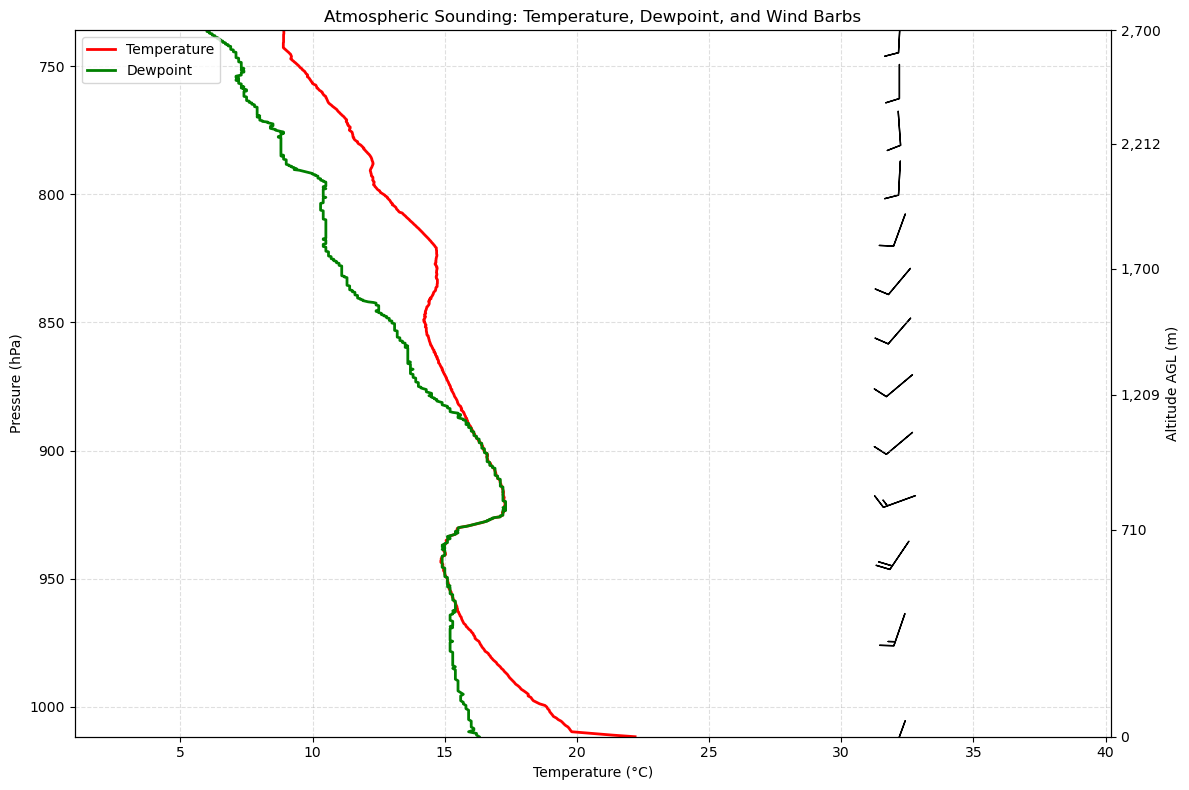

In [59]:
# Sounding plot: pressure (reversed), temperature, dewpoint, and a sparse set of wind barbs
press = pd.to_numeric(df['Pressure'], errors='coerce')
temp = pd.to_numeric(df['Temp'], errors='coerce')
dp = pd.to_numeric(df['DP'], errors='coerce')
alt = pd.to_numeric(df['Alt_AGL'], errors='coerce')
wdir = pd.to_numeric(df['WDirn'], errors='coerce')
wspeed = pd.to_numeric(df['WSpeed'], errors='coerce')

mask = press.notna() & temp.notna() & dp.notna() & alt.notna() & wdir.notna() & wspeed.notna()
press = press[mask].to_numpy()
temp = temp[mask].to_numpy()
dp = dp[mask].to_numpy()
alt = alt[mask].to_numpy()
wdir = wdir[mask].to_numpy()
wspeed = wspeed[mask].to_numpy()

# Convert wind direction (degrees from north) to u/v components
# Meteorological convention: direction is where wind is coming from
theta = np.deg2rad(wdir)
u = wspeed * np.sin(theta)
v = wspeed * np.cos(theta)

# Keep the wind barbs to a manageable subset instead of plotting every level
barb_idx = np.arange(0, len(press), max(1, len(press) // 12))

fig, ax = plt.subplots(figsize=(12, 8))

# Temperature and dewpoint profiles
ax.plot(temp, press, color='red', linewidth=2, label='Temperature')
ax.plot(dp, press, color='green', linewidth=2, label='Dewpoint')

# Pressure axis reversed so the atmosphere is plotted from high pressure at bottom
ax.set_ylim(press.max(), press.min())

# Wind barbs on the far right
xmax = max(temp.max(), dp.max())
xbarb = np.full_like(press[barb_idx], xmax + 10, dtype=float)
ax.barbs(xbarb, press[barb_idx], u[barb_idx], v[barb_idx], length=7, pivot='middle', color='k')

# Plot styling
ax.set_xlim(min(temp.min(), dp.min()) - 5, xmax + 18)
ax.set_xlabel('Temperature (°C)')
ax.set_ylabel('Pressure (hPa)')
ax.set_title('Atmospheric Sounding: Temperature, Dewpoint, and Wind Barbs')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper left')

# Add a secondary altitude axis on the right
axt = ax.twinx()
axt.set_ylim(ax.get_ylim())
axt.set_ylabel('Altitude AGL (m)')
if len(press) > 0:
    tick_idx = np.linspace(0, len(press) - 1, 6, dtype=int)
    axt.set_yticks(press[tick_idx])
    axt.set_yticklabels([f'{int(v):,}' for v in alt[tick_idx]])

plt.tight_layout()
plt.show()